# ACDC – Amazing Creative Desk Coworking
## Deliverable 1: Exploratory Data Analysis
**Data Mining · NOVA IMS · Fall 2026/27 · Group 31**

---

## Table of Contents

1. [Exploratory Data Analysis (EDA)](#1-exploratory-data-analysis-eda)  
2. [Data Cleaning and Preprocessing](#2-data-cleaning-and-preprocessing)  


---
## Students:
- Batoul Abdullah (20250536)  
- ??????  
- ?????

# 1.Exploratory Data Analysis (EDA)

In [33]:
#importing needed libraries 

In [34]:
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil
from scipy.stats import skewnorm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler


In [35]:
#importing the dataset :

In [36]:
acdc = pd.read_csv(r"C:\Users\batoul.abdullah\Downloads\acdc_dataset.csv" , sep=";")

In [37]:
#checking the characteristics of the data :

In [38]:
acdc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  object 
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  object 
 3   industry                     15465 non-null  object 
 4   country                      15035 non-null  object 
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  object 
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  object 
 10  membership_end               15465 non-null  object 
 11  last_badge_swipe             15465 non-null  object 
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits    

In [39]:
acdc.shape

(15465, 31)

In [40]:
#checking the datatypes :

In [41]:
acdc.dtypes

member_id                       object
age                            float64
gender                          object
industry                        object
country                         object
is_team_account                   bool
n_colleagues_on_account          int64
plan_tier                       object
plan_days_per_week               int64
membership_start                object
membership_end                  object
last_badge_swipe                object
days_since_last_visit            int64
total_visits                     int64
avg_weekly_visits              float64
entitled_visits_last_period    float64
actual_visits_last_period        int64
meeting_room_hours             float64
event_space_hours              float64
guest_passes_issued            float64
uses_meeting_rooms                bool
uses_event_space                  bool
uses_guest_passes                 bool
uses_print                       int64
uses_mail_handling                bool
uses_phone_booths        

In [42]:
num_cols = acdc.select_dtypes(include="number").columns.tolist()
acdc[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


**First observations**
- `lifetime_value` was not read as numeric: some values contain a thousands separator (e.g. `4,311.15`).
- Several numeric columns have **negative minimums** (visits, hours, renewals, colleagues), which is impossible.
- `age` ranges from 1 to 149, which is also impossible for coworking members.
- `uses_print` is stored as 0/1 while the other add-on flags are True/False.

In [43]:
acdc.head()

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74


In [44]:
#checking the duplicates 

In [45]:
n_full_dup = acdc.duplicated().sum()
n_id_dup = acdc["member_id"].duplicated().sum()
print(f"Fully duplicated rows: {n_full_dup}")
print(f"Duplicated member_id: {n_id_dup}")

Fully duplicated rows: 15
Duplicated member_id: 15


In [46]:
#checking the missing values :

In [47]:
acdc.isna().sum()

member_id                         0
age                             558
gender                          530
industry                          0
country                         430
is_team_account                   0
n_colleagues_on_account           0
plan_tier                       105
plan_days_per_week                0
membership_start                  0
membership_end                    0
last_badge_swipe                  0
days_since_last_visit             0
total_visits                      0
avg_weekly_visits                 0
entitled_visits_last_period       0
actual_visits_last_period         0
meeting_room_hours             1298
event_space_hours                 0
guest_passes_issued            1271
uses_meeting_rooms                0
uses_event_space                  0
uses_guest_passes                 0
uses_print                        0
uses_mail_handling                0
uses_phone_booths                 0
uses_day_passes                   0
uses_storage                

In [48]:
missing = acdc.isna().sum().to_frame("n_missing")
missing["pct"] = 100 * missing["n_missing"] / len(acdc)
missing = missing[missing["n_missing"] > 0].sort_values("pct", ascending=False)
missing

,n_missing,pct
meeting_room_hours,1298,8.393146
guest_passes_issued,1271,8.218558
lifetime_value,1040,6.724863
age,558,3.608147
gender,530,3.427093
country,430,2.780472
plan_tier,105,0.678952


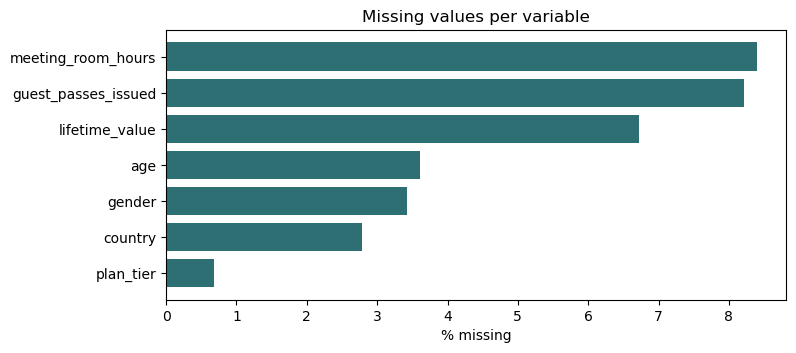

In [49]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(missing.index[::-1], missing["pct"][::-1], color="#2E6F73")
ax.set_xlabel("% missing"); ax.set_title("Missing values per variable")
plt.show()

In [50]:
## descriptive statistics :

In [51]:
acdc.describe(include='all').transpose()

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
member_id,15465,15450,CW005845,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,14907.0,NaN,NaN,NaN,34.858724,10.394649,1.0,29.0,34.0,40.0,149.0
gender,14935,12,Female,7414,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry,15465,43,Information Technology,3322,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,15035,33,Portugal,9959,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_team_account,15465,2,False,11112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_colleagues_on_account,15465.0,NaN,NaN,NaN,0.537019,1.177668,-1.0,0.0,0.0,1.0,9.0
plan_tier,15360,19,flex,5182,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan_days_per_week,15465.0,NaN,NaN,NaN,3.387262,1.458818,0.0,2.0,3.0,5.0,9.0
membership_start,15465,1539,2021-01-01,560,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [52]:
acdc.describe(include=object).transpose()

,count,unique,top,freq
member_id,15465,15450,CW005845,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


In [53]:
acdc['gender'].unique()

array(['Female', 'Male', 'F', 'Other', nan, ' Female', 'M', 'male',
       ' Male', 'other', ' Other', 'female', 'O'], dtype=object)

In [54]:
acdc['industry'].unique()

array(['Information Technology', 'Education', 'Legal', 'Health',
       'Unknown', 'Other', 'Consulting', 'Design & Creative',
       'information technology', 'Finance', 'Marketing & PR', 'EDUCATION',
       'DESIGN & CREATIVE', 'Marketing and PR', 'Real Estate', 'other',
       'consulting', 'MARKETING & PR', 'Information technology',
       'design & creative', 'LEGAL', 'marketing & pr',
       'INFORMATION TECHNOLOGY', 'health', 'Marketing/PR', 'CONSULTING',
       'unknown', 'Design/Creative', 'RealEstate', 'IT', 'Tech',
       'Marketing & Pr', 'OTHER', 'legal', 'finance', 'real estate',
       'education', 'Design and Creative', 'UNKNOWN', 'FINANCE',
       'REAL ESTATE', 'HEALTH', 'Real-Estate'], dtype=object)

In [55]:
acdc['country'].unique()

array(['Portugal', 'DE', 'portugal', 'United Kingdom', 'Spain', 'Germany',
       'Netherlands', 'France', 'PT', 'Other (Europe)', 'Portucal', nan,
       'UK', 'Ireland', 'United kingdom', 'IE', 'portugal ',
       'Deutschland', 'ireland', 'germany', 'france', 'united kingdom',
       'other (europe)', 'U.K.', 'GB', 'ES', 'NL', 'España', 'Espana',
       'netherlands', 'spain', 'The Netherlands', 'FR', 'Holland'],
      dtype=object)

In [56]:
acdc['plan_tier'].unique()

array(['flex', 'HOT_DESK', 'hot_desk', 'dedicated_desk', 'full_time',
       'private_office', 'Hot Desk', 'dedicateddesk', nan, 'FULL_TIME',
       'hotdesk', 'Flex', 'FLEX', 'fulltime', 'privateoffice',
       'Full Time', 'DEDICATED_DESK', 'Dedicated Desk', 'Private Office',
       'PRIVATE_OFFICE'], dtype=object)

In [57]:
for col in ["gender", "country", "industry", "plan_tier"]:
    print(f"{col}: {acdc[col].nunique()} distinct raw values")
    print(acdc[col].value_counts(dropna=False).head(15).to_dict(), "\n")

gender: 12 distinct raw values
{'Female': 7414, 'Male': 6172, nan: 530, 'Other': 465, 'female': 169, 'F': 143, ' Female': 141, 'M': 138, 'male': 132, ' Male': 129, 'other': 15, ' Other': 9, 'O': 8} 

country: 33 distinct raw values
{'Portugal': 9959, 'United Kingdom': 1105, 'Germany': 852, 'Spain': 712, 'France': 506, 'Netherlands': 464, nan: 430, 'Other (Europe)': 429, 'Ireland': 232, 'portugal ': 155, 'Portucal': 142, 'PT': 130, 'portugal': 122, 'germany': 24, 'other (europe)': 22} 

industry: 43 distinct raw values
{'Information Technology': 3322, 'Consulting': 1896, 'Marketing & PR': 1835, 'Design & Creative': 1822, 'Finance': 1134, 'Other': 1100, 'Legal': 809, 'Education': 727, 'Unknown': 640, 'Health': 571, 'Real Estate': 528, 'CONSULTING': 86, 'consulting': 76, 'INFORMATION TECHNOLOGY': 54, 'IT': 53} 

plan_tier: 19 distinct raw values
{'flex': 5182, 'hot_desk': 4974, 'full_time': 2323, 'dedicated_desk': 1481, 'private_office': 630, 'Flex': 138, 'FLEX': 133, nan: 105, 'HOT_DESK'

All four categorical variables contain the same concept spelled several ways (case, leading spaces, abbreviations such as PT, UK, DE, typos such as Portucal, local names such as Deutschland or España). They must be harmonised before any grouping.

### 4.4 Dates: mixed formats and a sentinel value

In [58]:
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]
for c in date_cols:
    s = acdc[c].astype(str)
    print(f"{c}: ISO (yyyy-mm-dd) = {s.str.match(r'^\d{4}-').sum():,} | dd/mm/yyyy = {s.str.match(r'^\d{2}/').sum():,}")
print("\nmembership_end == 1970-01-01:", (acdc["membership_end"] == "1970-01-01").sum())

membership_start: ISO (yyyy-mm-dd) = 14,826 | dd/mm/yyyy = 639
membership_end: ISO (yyyy-mm-dd) = 15,002 | dd/mm/yyyy = 463
last_badge_swipe: ISO (yyyy-mm-dd) = 14,826 | dd/mm/yyyy = 639

membership_end == 1970-01-01: 3956


- Two date formats coexist. Values such as `31/12/2021` confirm the slash format is **day/month/year**.
- `1970-01-01` (the Unix epoch) appears in about a quarter of `membership_end`. This is not a real date; it is a **placeholder for memberships that have not ended**, i.e. **active members**. We confirm this below: for those rows, `days_since_last_visit` is consistent with a reference date of 2024-01-01 (data extraction).

In [59]:
def parse_mixed_dates(s):
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    dmy = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    return iso.fillna(dmy)

tmp = acdc[date_cols].apply(parse_mixed_dates)
active = tmp["membership_end"].dt.year == 1970
REF_DATE = pd.Timestamp("2024-01-01")
end_or_ref = tmp["membership_end"].where(~active, REF_DATE)
recomputed = (end_or_ref - tmp["last_badge_swipe"]).dt.days
match = (recomputed == acdc["days_since_last_visit"]).mean()
print(f"days_since_last_visit = (membership_end or 2024-01-01) − last_badge_swipe for {match:.1%} of rows")
print(f"Memberships start between {tmp['membership_start'].min().date()} and {tmp['membership_start'].max().date()}")
print(f"Badge swipes after the 2024-01-01 extraction date: {(tmp['last_badge_swipe'] > REF_DATE).sum()}")

days_since_last_visit = (membership_end or 2024-01-01) − last_badge_swipe for 85.4% of rows
Memberships start between 2021-01-01 and 2023-12-30
Badge swipes after the 2024-01-01 extraction date: 34


### 4.5 Impossible or suspicious values

In [60]:
checks = {
    "age < 18": (acdc["age"] < 18).sum(),
    "age > 80": (acdc["age"] > 80).sum(),
    "negative total_visits": (acdc["total_visits"] < 0).sum(),
    "negative meeting_room_hours": (acdc["meeting_room_hours"] < 0).sum(),
    "negative event_space_hours": (acdc["event_space_hours"] < 0).sum(),
    "negative guest_passes_issued": (acdc["guest_passes_issued"] < 0).sum(),
    "negative n_renewals": (acdc["n_renewals"] < 0).sum(),
    "negative n_colleagues": (acdc["n_colleagues_on_account"] < 0).sum(),
    "negative days_since_last_visit": (acdc["days_since_last_visit"] < 0).sum(),
    "plan_days_per_week not in {2,3,5,7}": (~acdc["plan_days_per_week"].isin([2, 3, 5, 7])).sum(),
    "membership_end < membership_start": ((tmp["membership_end"] < tmp["membership_start"]) & ~active).sum(),
    "last_badge_swipe < membership_start": (tmp["last_badge_swipe"] < tmp["membership_start"]).sum(),
    "last_badge_swipe after extraction date": (tmp["last_badge_swipe"] > REF_DATE).sum(),
}
pd.Series(checks, name="n_rows").to_frame()

,n_rows
age < 18,98
age > 80,53
negative total_visits,42
negative meeting_room_hours,16
negative event_space_hours,8
negative guest_passes_issued,7
negative n_renewals,66
negative n_colleagues,566
negative days_since_last_visit,56
"plan_days_per_week not in {2,3,5,7}",97


### 4.6 Plan tier ↔ plan days per week

Cross-tabulates tier and days per week. Each tier has exactly one valid number of days, so the two columns carry the same information and can repair each other.

In [61]:
tier_key = acdc["plan_tier"].str.lower().str.replace(r"[\s_]", "", regex=True)
pd.crosstab(tier_key, acdc["plan_days_per_week"])

plan_days_per_week,0,2,3,5,7,9
plan_tier,,,,,,
dedicateddesk,3,0,0,1543,0,6
flex,20,0,5411,0,0,22
fulltime,5,0,0,2460,0,10
hotdesk,14,5186,0,0,0,15
privateoffice,1,0,0,0,663,1


Each tier maps to **exactly one** entitlement (hot_desk = 2, flex = 3, dedicated_desk = 5, full_time = 5, private_office = 7). The few 0 and 9 values are entry errors, and missing plan_tier can be recovered from plan_days_per_week when that value is unambiguous (2, 3 or 7).

 plan_days_per_week is therefore **redundant** with plan_tier and should not enter the clustering as an independent variable.

# 2.Data Cleaning and Preprocessing

from the above Exploration and for better analysis we decided to do the following steps :

#### 2.1 # Remove duplicates 


In [68]:
# Remove exact duplicate rows and work on a copy of the data
acdcc = acdc.drop_duplicates().copy()
print(f"Rows removed: {len(acdc) - len(acdcc)}")

Rows removed: 15


#### 2.2 # Mapping dictionaries & Harmonise categories 

In [69]:
# Dictionaries that map every spelling variant to one standard category
GENDER_MAP = {"female": "Female", "f": "Female", "male": "Male", "m": "Male",
              "other": "Other", "o": "Other"}

COUNTRY_MAP = {
    "portugal": "Portugal", "portucal": "Portugal", "pt": "Portugal",
    "united kingdom": "United Kingdom", "uk": "United Kingdom", "u.k.": "United Kingdom", "gb": "United Kingdom",
    "germany": "Germany", "deutschland": "Germany", "de": "Germany",
    "spain": "Spain", "espana": "Spain", "españa": "Spain", "es": "Spain",
    "france": "France", "fr": "France",
    "netherlands": "Netherlands", "the netherlands": "Netherlands", "holland": "Netherlands", "nl": "Netherlands",
    "ireland": "Ireland", "ie": "Ireland",
    "other (europe)": "Other (Europe)",
}

INDUSTRY_MAP = {
    "information technology": "Information Technology", "it": "Information Technology", "tech": "Information Technology",
    "consulting": "Consulting",
    "marketing & pr": "Marketing & PR", "marketing/pr": "Marketing & PR", "marketing and pr": "Marketing & PR",
    "design & creative": "Design & Creative", "design/creative": "Design & Creative", "design and creative": "Design & Creative",
    "finance": "Finance", "legal": "Legal", "education": "Education", "health": "Health",
    "real estate": "Real Estate", "realestate": "Real Estate", "real-estate": "Real Estate",
    "other": "Other", "unknown": np.nan,   # 'Unknown' is a missing value in disguise
}

TIER_MAP = {"hotdesk": "hot_desk", "flex": "flex", "dedicateddesk": "dedicated_desk",
            "fulltime": "full_time", "privateoffice": "private_office"}
TIER_ORDER = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]
TIER_DAYS = {"hot_desk": 2, "flex": 3, "dedicated_desk": 5, "full_time": 5, "private_office": 7}

In [78]:
# Strip spaces + lowercase, then map each variant to its standard name

def norm(s):
    return s.astype("string").str.strip().str.lower()

acdcc["gender"] = norm(acdcc["gender"]).map(GENDER_MAP)
acdcc["country"] = norm(acdcc["country"]).map(COUNTRY_MAP)
acdcc["industry"] = norm(acdcc["industry"]).map(INDUSTRY_MAP)
acdcc["plan_tier"] = norm(acdcc["plan_tier"]).str.replace(r"[\s_]", "", regex=True).map(TIER_MAP)

for col in ["gender", "country", "industry", "plan_tier"]:
    print(f"{col}: {acdcc[col].nunique()} categories")

gender: 3 categories
country: 8 categories
industry: 10 categories
plan_tier: 5 categories


#### 2.3 # Repair plan tier and days per week

In [80]:
# Each tier has exactly one valid number of days, so they can repair each other

# 1) invalid days (0, 9) -> missing, then fill from tier
acdcc.loc[~acdcc["plan_days_per_week"].isin([2, 3, 5, 7]), "plan_days_per_week"] = np.nan
acdcc["plan_days_per_week"] = acdcc["plan_days_per_week"].fillna(acdcc["plan_tier"].map(TIER_DAYS))

# 2) missing tier -> recover from days (only 2, 3, 7; 5 is ambiguous can either be full_time or dedicated-desk)
days_to_tier = {2: "hot_desk", 3: "flex", 7: "private_office"}
acdcc["plan_tier"] = acdcc["plan_tier"].fillna(acdcc["plan_days_per_week"].map(days_to_tier))

# 3) ordered category: cheapest -> most expensive
acdcc["plan_tier"] = pd.Categorical(acdcc["plan_tier"], categories=TIER_ORDER, ordered=True)

#### 3.3 # Numeric formats 

In [82]:
# Remove thousands separator from lifetime_value and convert to number
acdcc["lifetime_value"] = pd.to_numeric(acdcc["lifetime_value"].astype(str).str.replace(",", ""),
                                      errors="coerce")
# uses_print is 0/1; convert to True/False like the other add-on flags
acdcc["uses_print"] = acdcc["uses_print"].astype(bool)

#### 3.4 #  Dates and active flag

In [87]:
# Two date formats coexist: yyyy-mm-dd and dd/mm/yyyy
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]
REF_DATE = pd.Timestamp("2024-01-01")   # data extraction date

def parse_mixed_dates(s):
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    dmy = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    return iso.fillna(dmy)

for c in date_cols:
    acdcc[c] = parse_mixed_dates(acdcc[c].astype(str))

# 1970-01-01 is a placeholder meaning the membership has not ended -> active member
acdcc["is_active"] = acdcc["membership_end"].dt.year == 1970
acdcc.loc[acdcc["is_active"], "membership_end"] = pd.NaT
print(acdcc["is_active"].value_counts(normalize=True))

is_active
False    0.744078
True     0.255922
Name: proportion, dtype: float64


#### 3.5 #  Impossible values → missing

In [88]:
# Age outside 18–80 is not realistic for coworking members
acdcc.loc[(acdcc["age"] < 18) | (acdcc["age"] > 80), "age"] = np.nan

# Counts, hours and money cannot be negative
non_negative = ["total_visits", "meeting_room_hours", "event_space_hours", "guest_passes_issued",
                "n_renewals", "n_colleagues_on_account", "lifetime_value", "days_since_last_visit"]
for c in non_negative:
    acdcc.loc[acdcc[c] < 0, c] = np.nan

# Flag (we did not delete) inconsistent dates
acdcc["date_inconsistency"] = ((acdcc["membership_end"] < acdcc["membership_start"])
                             | (acdcc["last_badge_swipe"] < acdcc["membership_start"])
                             | (acdcc["last_badge_swipe"] > REF_DATE))
print("Rows with date inconsistency:", acdcc["date_inconsistency"].sum())

Rows with date inconsistency: 279


#### 3.6 #  Structural zeros

In [91]:
# If the member never used the add-on, a missing usage value is really 0
acdcc.loc[acdcc["meeting_room_hours"].isna() & ~acdcc["uses_meeting_rooms"], "meeting_room_hours"] = 0
acdcc.loc[acdcc["guest_passes_issued"].isna() & ~acdcc["uses_guest_passes"], "guest_passes_issued"] = 0

#### 3.7 # Check result

In [90]:
acdcc = acdcc.reset_index(drop=True)
print(f"Rows after cleaning: {len(acdcc):,}")
remaining = acdcc.isna().sum()
remaining[remaining > 0].sort_values(ascending=False).to_frame("missing_after_cleaning")

Rows after cleaning: 15,450


,missing_after_cleaning
membership_end,3954
lifetime_value,1413
age,708
industry,693
n_colleagues_on_account,565
gender,530
country,429
meeting_room_hours,409
guest_passes_issued,210
n_renewals,66


## 4. Univariate Analysis

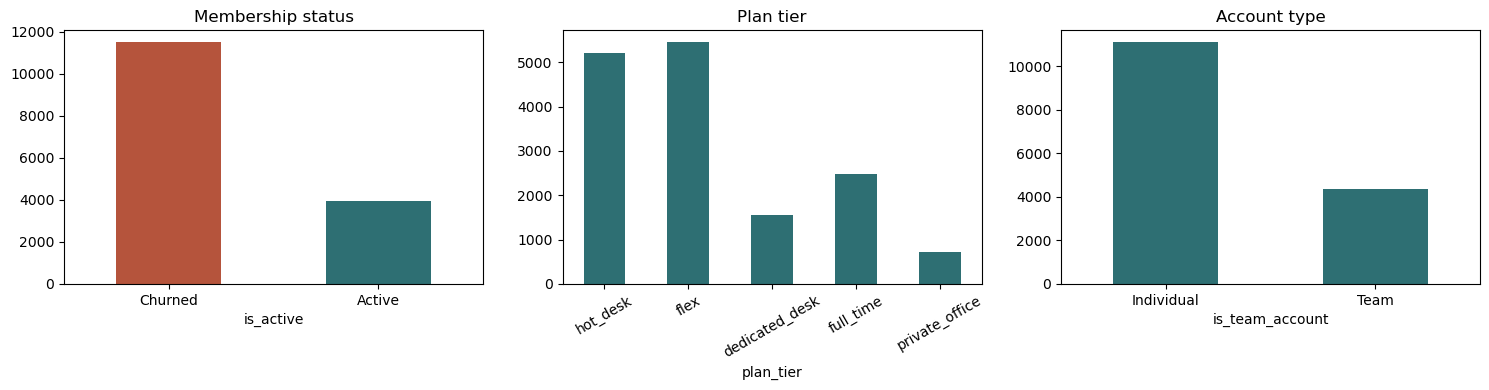

is_active
churned    0.744078
active     0.255922
Name: proportion, dtype: float64


In [96]:
#Distribution of membership status, plan tier and account type.

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
acdcc["is_active"].map({True: "Active", False: "Churned"}).value_counts().plot.bar(ax=axes[0], color=["#B5543C", "#2E6F73"])
axes[0].set_title("Membership status"); axes[0].tick_params(axis="x", rotation=0)
acdcc["plan_tier"].value_counts().reindex(TIER_ORDER).plot.bar(ax=axes[1], color="#2E6F73")
axes[1].set_title("Plan tier"); axes[1].tick_params(axis="x", rotation=30)
acdcc["is_team_account"].map({True: "Team", False: "Individual"}).value_counts().plot.bar(ax=axes[2], color="#2E6F73")
axes[2].set_title("Account type"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print(acdcc["is_active"].value_counts(normalize=True).rename({True: "active", False: "churned"}))

In [137]:
#Numeric distributions

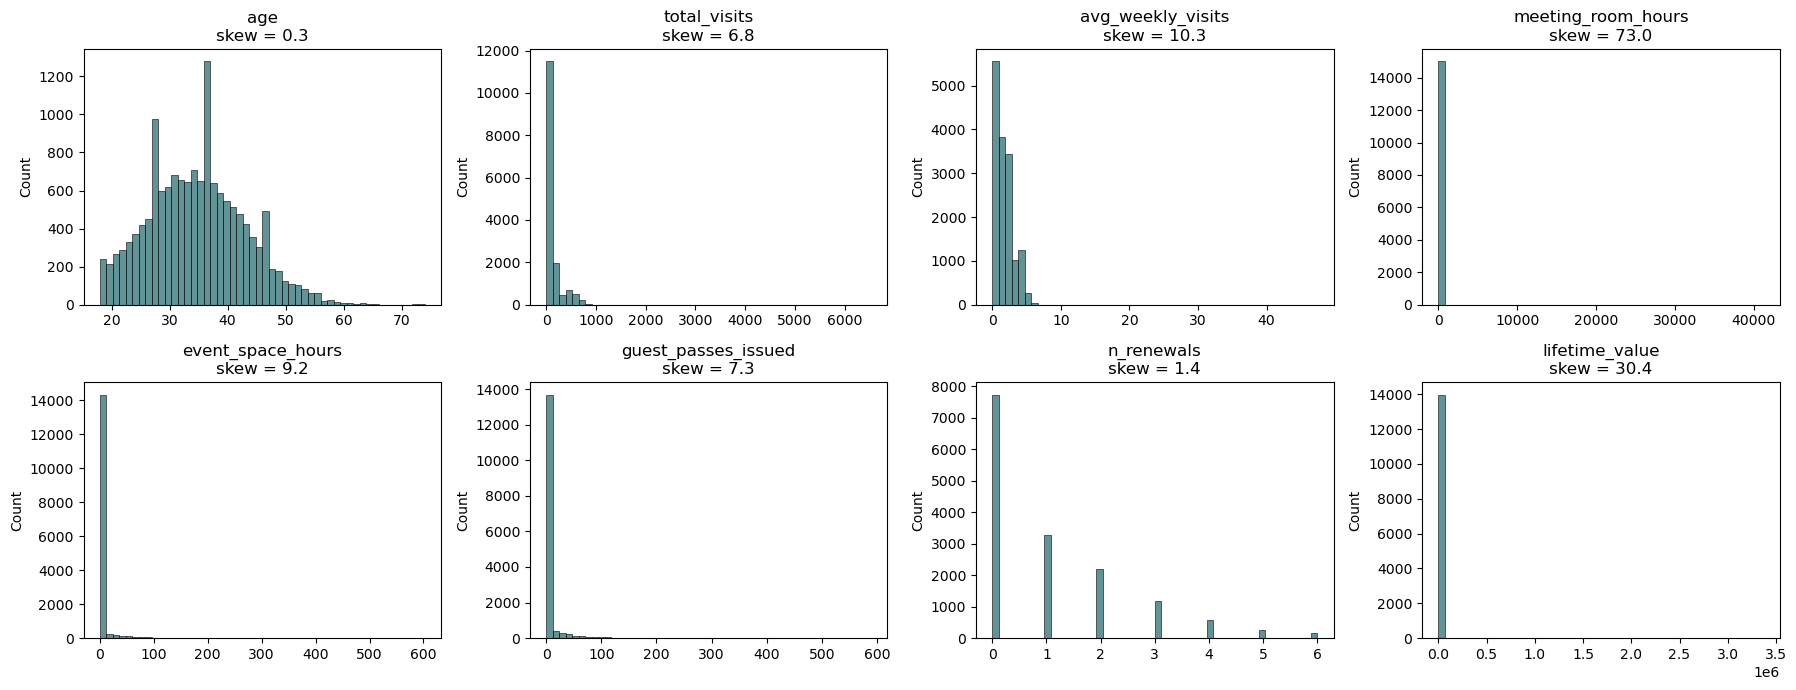

In [136]:
dist_cols = ["age", "total_visits", "avg_weekly_visits", "meeting_room_hours", "event_space_hours",
             "guest_passes_issued", "n_renewals", "lifetime_value"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.flat, dist_cols):
    sns.histplot(acdcc[c].dropna(), bins=50, ax=ax, color="#2E6F73")
    ax.set_title(f"{c}\nskew = {acdcc[c].skew():.1f}")
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

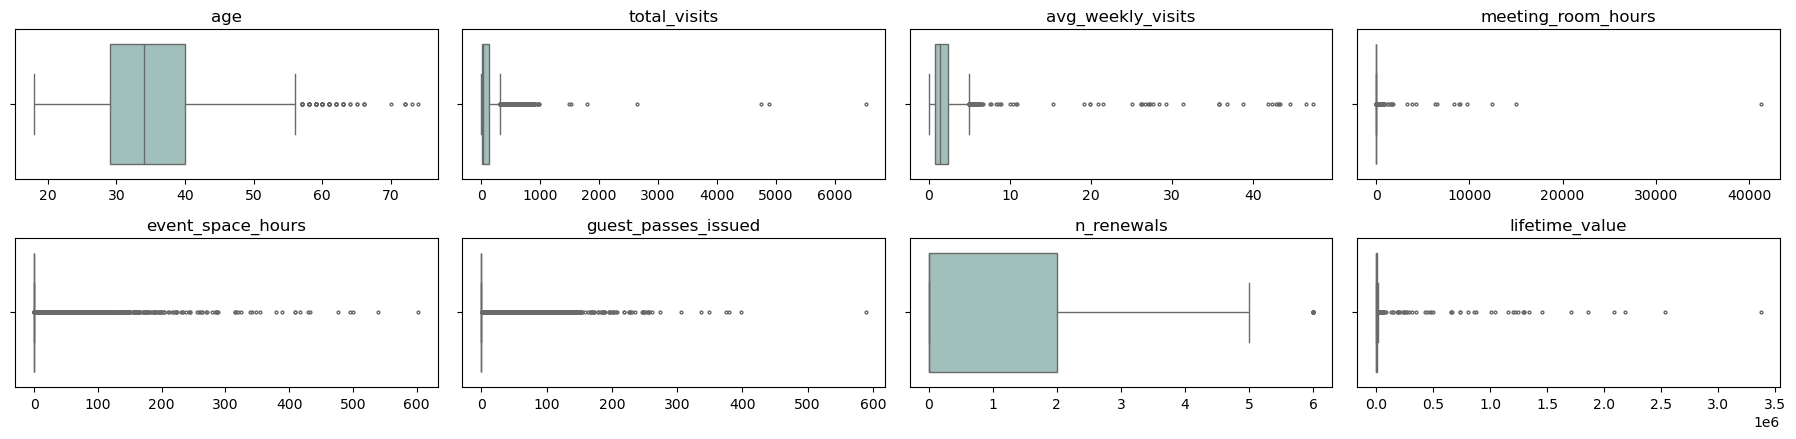

In [138]:
fig, axes = plt.subplots(2, 4, figsize=(18, 4.5))
for ax, c in zip(axes.flat, dist_cols):
    sns.boxplot(x=acdcc[c].dropna(), ax=ax, color="#9CC5C0", fliersize=2)
    ax.set_title(c); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [100]:
q = acdcc[dist_cols].quantile([0.5, 0.99, 1.0]).T
q.columns = ["median", "p99", "max"]
q["max / p99"] = q["max"] / q["p99"]
q

,median,p99,max,max / p99
age,34.00,55.0000,74.0,1.345455
total_visits,35.00,693.9300,6530.0,9.410171
avg_weekly_visits,1.42,5.3200,47.4,8.909774
meeting_room_hours,0.00,319.9200,41220.0,128.844711
event_space_hours,0.00,127.4390,602.8,4.730106
guest_passes_issued,0.00,115.0000,589.0,5.121739
n_renewals,0.00,5.0000,6.0,1.200000
lifetime_value,901.86,25729.6652,3371260.0,131.026190


Usage and value variables are **heavily right-skewed**, with a few extreme values far beyond the 99th percentile (e.g. `meeting_room_hours`, `lifetime_value`, `total_visits`). These would dominate distance-based algorithms such as K-Means. Options for Deliverable 2: log transform, winsorising at p99, or a robust scaler — and checking whether the extremes are data errors or genuine VIP accounts.

In [142]:
# Count outliers per variable using the IQR rule (detection only, nothing removed)
out_cols = ["total_visits", "meeting_room_hours", "event_space_hours",
            "guest_passes_issued", "lifetime_value"]

rows = []
for c in out_cols:
    q1, q3 = acdcc[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    n_out = (acdcc[c] > upper).sum()
    rows.append({"variable": c, "upper_limit": upper, "n_outliers": n_out,
                 "pct_outliers": 100 * n_out / acdcc[c].notna().sum()})

pd.DataFrame(rows)

,variable,upper_limit,n_outliers,pct_outliers
0,total_visits,318.00,1730,11.227934
1,meeting_room_hours,12.00,3250,21.607606
2,event_space_hours,0.00,1759,11.391012
3,guest_passes_issued,0.00,2477,16.253281
4,lifetime_value,12522.16,1135,8.085773


Several variables have a large share of outliers, which confirms the strong right skew seen in the histograms. Since these can be real high-value members, we keep them for now and will decide in Deliverable 2 whether to apply a log transform, winsorise them, or analyse them separately.

In [144]:
#Add-on adoption

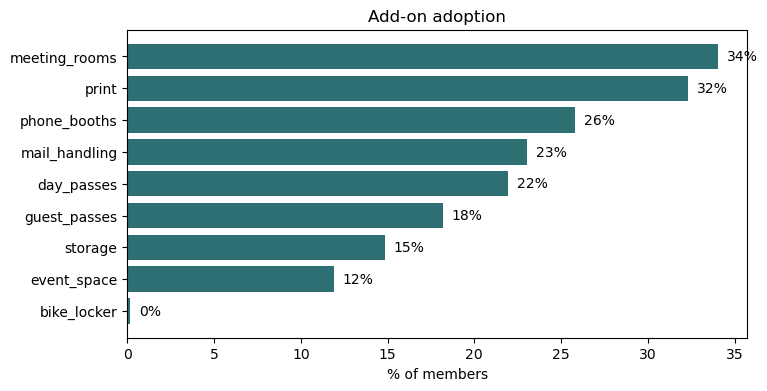

In [103]:
#Share of members using each add-on.
addon_cols = [c for c in acdcc.columns if c.startswith("uses_")]
adoption = acdcc[addon_cols].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(adoption.index.str.replace("uses_", ""), adoption * 100, color="#2E6F73")
ax.set_xlabel("% of members"); ax.set_title("Add-on adoption")
for i, v in enumerate(adoption * 100):
    ax.text(v + 0.5, i, f"{v:.0f}%", va="center")
plt.show()

Meeting rooms are the most used add-on (~34%). `uses_bike_locker` is almost constant (< 0.2%) and carries no information for clustering, so it is a candidate for removal.

In [143]:
#Demographics

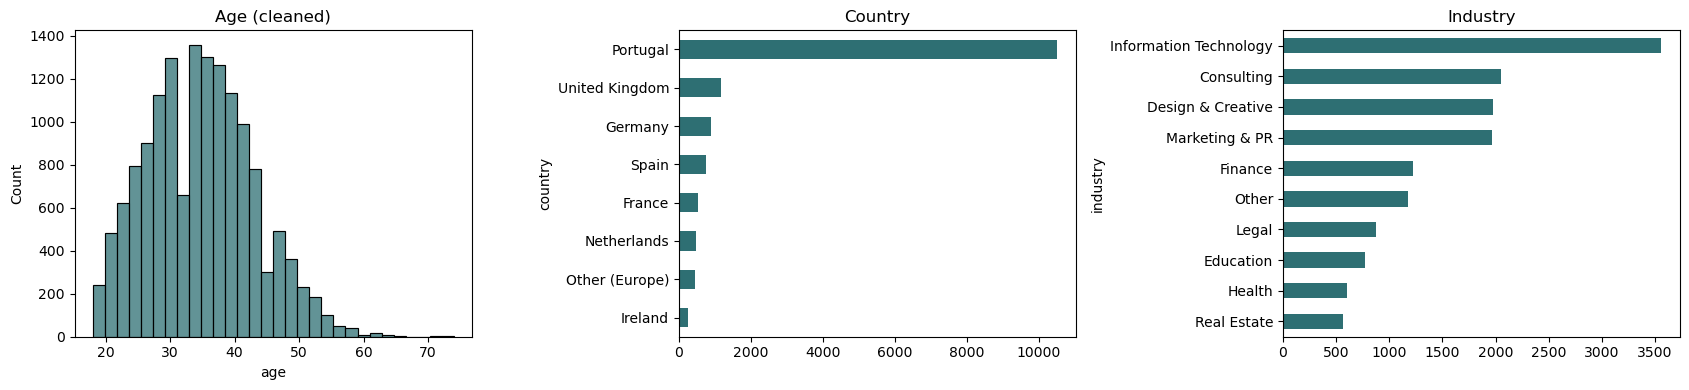

In [105]:

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(acdcc["age"].dropna(), bins=30, ax=axes[0], color="#2E6F73"); axes[0].set_title("Age (cleaned)")
acdcc["country"].value_counts().plot.barh(ax=axes[1], color="#2E6F73"); axes[1].set_title("Country"); axes[1].invert_yaxis()
acdcc["industry"].value_counts().plot.barh(ax=axes[2], color="#2E6F73"); axes[2].set_title("Industry"); axes[2].invert_yaxis()
plt.tight_layout(); plt.show()

About two-thirds of members are based in Portugal; IT, Consulting, Marketing & PR and Design & Creative are the largest industries.

## 5. Bivariate Analysis

In [106]:
#Value by plan tier
#Summary per tier: members, median lifetime value, total revenue, share still active. 
#Comparing share of members with share of revenue shows where value is concentrated.

tier_summary = acdcc.groupby("plan_tier", observed=True).agg(
    members=("member_id", "count"),
    median_ltv=("lifetime_value", "median"),
    total_ltv=("lifetime_value", "sum"),
    active_rate=("is_active", "mean"),
    median_renewals=("n_renewals", "median"),
)
tier_summary["share_members"] = tier_summary["members"] / tier_summary["members"].sum()
tier_summary["share_revenue"] = tier_summary["total_ltv"] / tier_summary["total_ltv"].sum()
tier_summary

,members,median_ltv,total_ltv,active_rate,median_renewals,share_members,share_revenue
plan_tier,,,,,,,
hot_desk,5212,321.305,9682415.84,0.133538,0.0,0.338420,0.107388
flex,5449,1253.810,18156877.90,0.202606,0.0,0.353808,0.201379
dedicated_desk,1549,10387.850,19091408.32,0.565526,2.0,0.100578,0.211744
full_time,2471,4694.105,22494119.19,0.376366,1.0,0.160444,0.249484
private_office,720,19905.690,20737813.43,0.455556,2.0,0.046750,0.230005


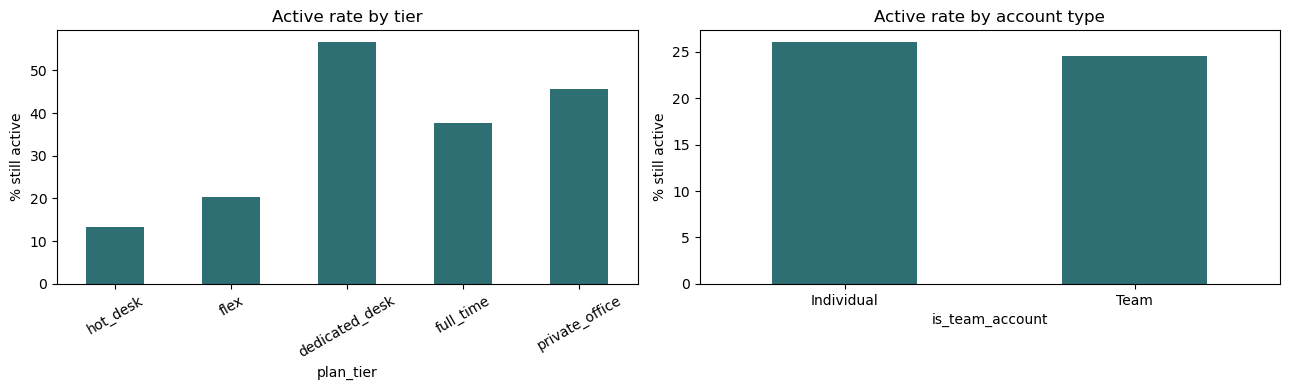

In [108]:
#Churn by tier and account type
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
(acdcc.groupby("plan_tier", observed=True)["is_active"].mean() * 100).plot.bar(ax=axes[0], color="#2E6F73")
axes[0].set_ylabel("% still active"); axes[0].set_title("Active rate by tier"); axes[0].tick_params(axis="x", rotation=30)
(acdcc.groupby("is_team_account")["is_active"].mean() * 100).rename({True: "Team", False: "Individual"}).plot.bar(ax=axes[1], color="#2E6F73")
axes[1].set_ylabel("% still active"); axes[1].set_title("Active rate by account type"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

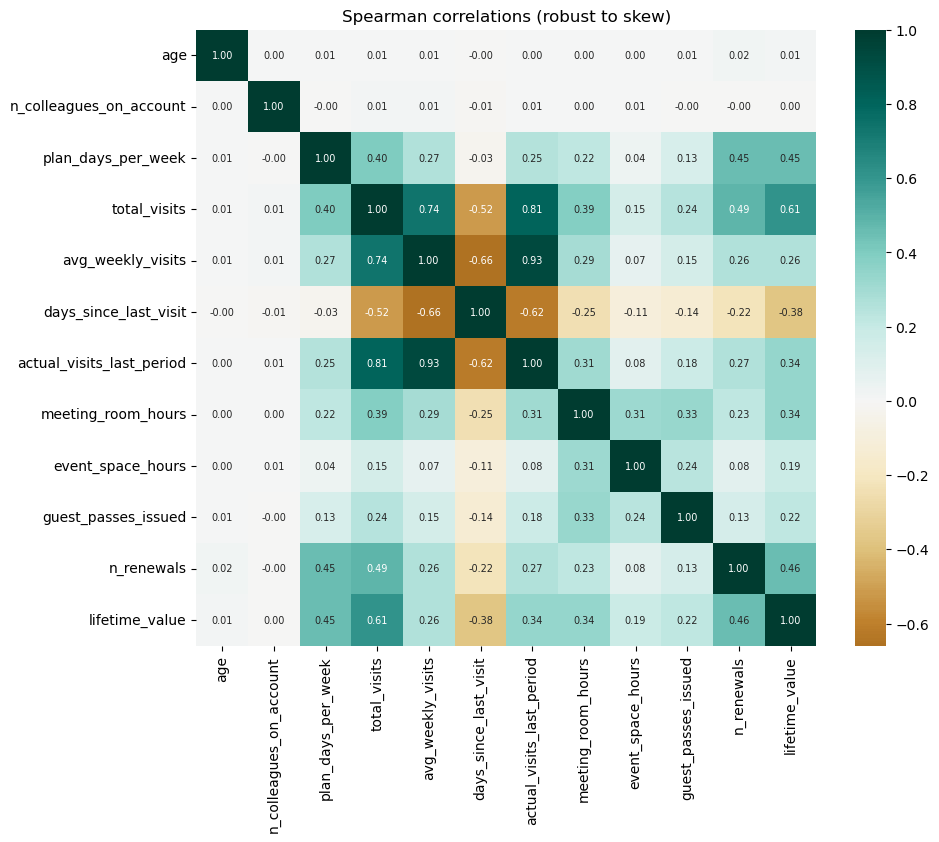

In [109]:
#Correlations
corr_cols = ["age", "n_colleagues_on_account", "plan_days_per_week", "total_visits", "avg_weekly_visits",
             "days_since_last_visit", "actual_visits_last_period", "meeting_room_hours", "event_space_hours",
             "guest_passes_issued", "n_renewals", "lifetime_value"]
corr = acdcc[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="BrBG", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlations (robust to skew)")
plt.show()

We use **Spearman** because of the strong skew. Strongly correlated pairs (e.g. `total_visits` with `n_renewals` and `lifetime_value`, which all grow with tenure) mean that several raw variables mostly measure **how long someone has been a member**. Feeding all of them to a clustering algorithm would over-weight tenure. This motivates the normalised features in Section 8.

## 6. Feature Engineering



Most usage and value variables in the dataset are cumulative: total visits, renewals and lifetime value all keep growing the longer someone is a member. This means they mostly reflect tenure, not how intensively a member uses or pays for the space. A member who joined three years ago will always look "bigger" than one who joined three months ago, even if the newer member is more active.

To compare members fairly, we created new features that separate intensity from time:

| Feature | Definition | Perspective | What it shows |
|---|---|---|---|
| `tenure_months` | (end date, or 2024-01-01 if active) − start date, in months | Value | How long the member has stayed |
| `ltv_per_month` | lifetime_value ÷ tenure_months | Value | How much the member pays per month |
| `visits_per_month` | total_visits ÷ tenure_months | Behavioral | How often the member comes |
| `meeting_hours_per_month` | meeting_room_hours ÷ tenure_months | Behavioral | Collaborative or client-facing work |
| `renewal_rate` | n_renewals ÷ tenure_months × 12 | Value | Commitment (renewals per year) |
| `utilisation_rate` | actual ÷ entitled visits in the last period | Behavioral | Whether the member uses the days they pay for |
| `n_addons` | number of add-ons used (0–8) | Behavioral | Breadth of service use |
| `account_size` | n_colleagues_on_account + 1 | Value | Number of people on the account |
| `ltv_per_seat` | lifetime_value ÷ account_size | Value | Revenue per person |

Active members have no end date, so their tenure is calculated up to the data extraction date (2024-01-01). A tenure of zero or less is set to missing to avoid dividing by zero.

In [111]:
# Work on a copy so the cleaned data stays unchanged
feat = acdcc.copy()

#### New Features :

In [112]:
# Active members have no end date, so we use the extraction date instead
end = feat["membership_end"].fillna(REF_DATE)
feat["tenure_months"] = (end - feat["membership_start"]).dt.days / 30.44

# A tenure of 0 or less is not valid (we cannot divide by it)
feat.loc[feat["tenure_months"] <= 0, "tenure_months"] = np.nan

In [113]:
# Divide cumulative totals by tenure to measure intensity, not time
feat["ltv_per_month"] = feat["lifetime_value"] / feat["tenure_months"]
feat["visits_per_month"] = feat["total_visits"] / feat["tenure_months"]
feat["meeting_hours_per_month"] = feat["meeting_room_hours"] / feat["tenure_months"]
feat["renewal_rate"] = feat["n_renewals"] / feat["tenure_months"] * 12   # renewals per year

In [114]:
# Actual visits divided by the visits the plan allows (last period)
# replace(0, np.nan) avoids dividing by zero
feat["utilisation_rate"] = (feat["actual_visits_last_period"] /
                            feat["entitled_visits_last_period"].replace(0, np.nan))

In [115]:
# Number of add-ons each member uses (True = 1, False = 0)
addon_cols = [c for c in feat.columns if c.startswith("uses_")]
feat["n_addons"] = feat[addon_cols].sum(axis=1)

# Seats on the account (colleagues + the member) and revenue per seat
feat["account_size"] = feat["n_colleagues_on_account"].fillna(0) + 1
feat["ltv_per_seat"] = feat["lifetime_value"] / feat["account_size"]

In [116]:
eng_cols = ["tenure_months", "ltv_per_month", "visits_per_month", "utilisation_rate",
            "n_addons", "meeting_hours_per_month", "renewal_rate", "account_size", "ltv_per_seat"]
feat[eng_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure_months,15298.0,12.307675,11.132983,0.065703,2.135348,9.280552,20.926413,3.597240e+01
ltv_per_month,13906.0,417.412011,2832.198871,0.000000,128.367118,190.726141,307.122459,9.371795e+04
visits_per_month,15256.0,7.471535,6.501514,0.000000,3.044000,6.088000,10.394146,2.065571e+02
utilisation_rate,15440.0,0.517532,0.312207,0.000000,0.238996,0.517539,0.804906,1.000000e+00
n_addons,15450.0,1.822783,1.504320,0.000000,1.000000,1.000000,3.000000,8.000000e+00
meeting_hours_per_month,14894.0,1.853783,20.482172,0.000000,0.000000,0.000000,0.826080,1.842492e+03
renewal_rate,15233.0,2.174342,14.931593,0.000000,0.000000,0.000000,1.283185,9.132000e+02
account_size,15450.0,1.573722,1.144505,1.000000,1.000000,1.000000,2.000000,1.000000e+01
ltv_per_seat,14037.0,5412.281760,58439.055894,0.000000,186.580000,653.150000,3955.157500,3.371260e+06


In [117]:
# Compare medians between active and churned members
cmp = feat.groupby("is_active")[["utilisation_rate", "visits_per_month", "n_addons",
                                 "ltv_per_month", "renewal_rate"]].median().T
cmp.columns = ["Churned", "Active"]
cmp

,Churned,Active
utilisation_rate,0.574933,0.232019
visits_per_month,7.079070,3.611525
n_addons,1.000000,2.000000
ltv_per_month,183.797465,249.892761
renewal_rate,0.000000,0.800614


*Finding:* Active members have a much lower utilisation rate (about 23%) than churned members (about 57%), and they also visit less per month. At the same time, they use more add-ons, pay more per month and renew more often.

This shows that members who stay are mostly premium and team accounts (private office, full time) who pay for guaranteed space rather than daily attendance. In contrast, hot-desk and flex members tend to come often for a period and then leave.

This means utilisation alone is not a measure of engagement: it has to be read together with plan tier and account type. These features will be the main inputs for the value and behavioral perspectives in Deliverable 2.

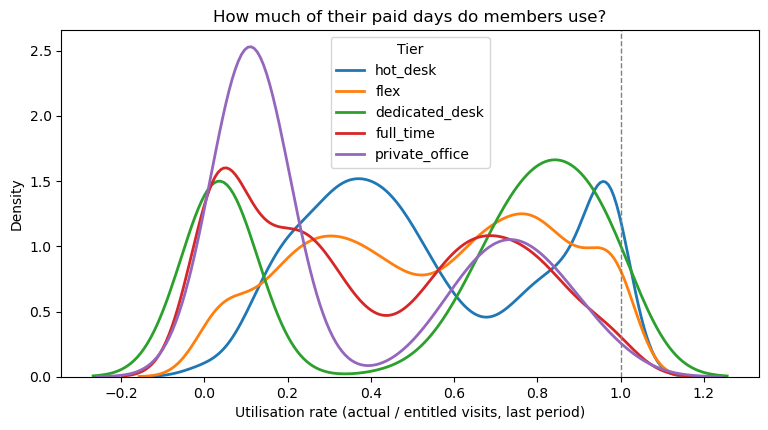

,median_utilisation
plan_tier,
hot_desk,0.464576
flex,0.574933
dedicated_desk,0.735971
full_time,0.333048
private_office,0.147856


In [131]:
# Distribution of utilisation for each plan tier

fig, ax = plt.subplots(figsize=(9, 4.5))
for tier in TIER_ORDER:
    s = feat.loc[feat["plan_tier"] == tier, "utilisation_rate"].clip(upper=1.5).dropna()
    sns.kdeplot(s, ax=ax, label=tier, linewidth=2)
ax.axvline(1, color="grey", ls="--", lw=1)   # 1 = used every paid day
ax.set_xlabel("Utilisation rate (actual / entitled visits, last period)")
ax.set_title("How much of their paid days do members use?")
ax.legend(title="Tier")
plt.show()

feat.groupby("plan_tier", observed=True)["utilisation_rate"].median().to_frame("median_utilisation")

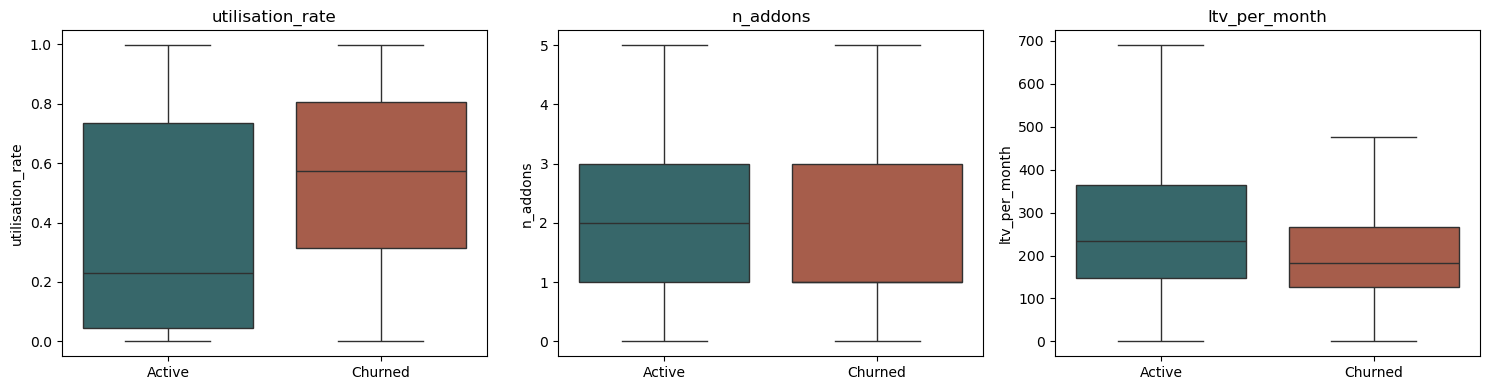

In [132]:
# Compare key features between active and churned members
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["utilisation_rate", "n_addons", "ltv_per_month"]):
    data = feat[[c, "is_active"]].dropna()
    data["status"] = data["is_active"].map({True: "Active", False: "Churned"})
    upper = data[c].quantile(0.98)             
    sns.boxplot(data=data[data[c] <= upper], x="status", y=c, hue="status", legend=False,
                order=["Active", "Churned"], ax=ax,
                palette={"Active": "#2E6F73", "Churned": "#B5543C"}, showfliers=False)
    ax.set_title(c)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

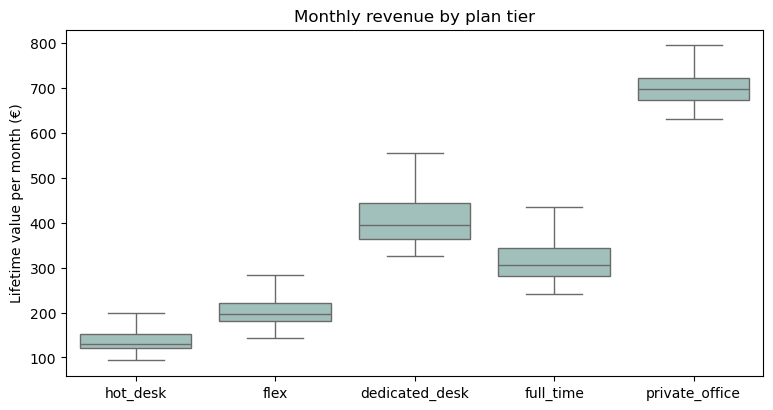

,median_ltv_per_month
plan_tier,
hot_desk,129.304962
flex,197.431912
dedicated_desk,394.646144
full_time,304.964994
private_office,697.773068


In [133]:
# Revenue per month for each plan tier
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=feat, x="plan_tier", y="ltv_per_month", order=TIER_ORDER,
            showfliers=False, color="#9CC5C0", ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Lifetime value per month (€)")
ax.set_title("Monthly revenue by plan tier")
plt.show()

feat.groupby("plan_tier", observed=True)["ltv_per_month"].median().to_frame("median_ltv_per_month")

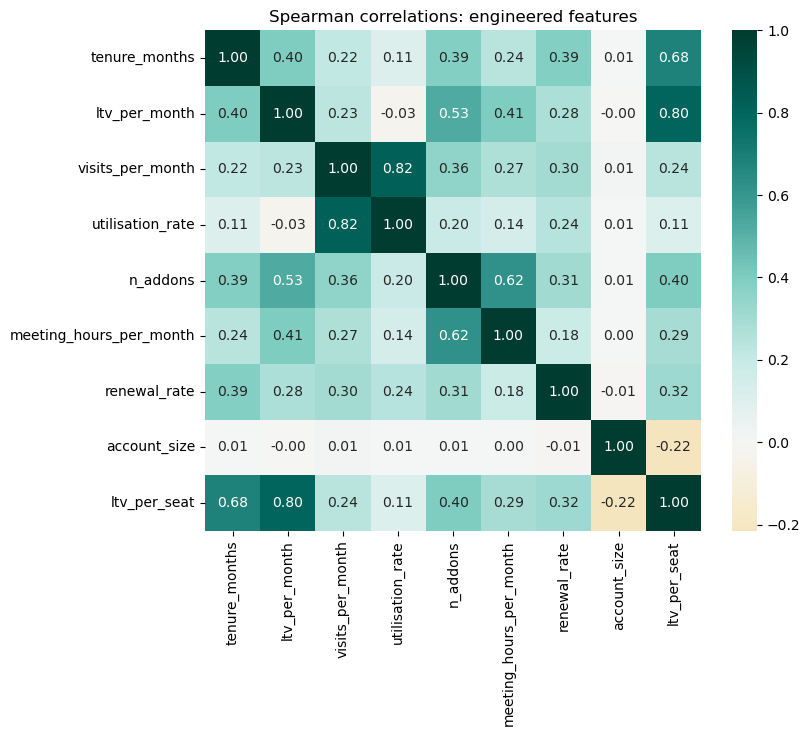

In [134]:
# Check that the engineered features are not copies of each other
eng_cols = ["tenure_months", "ltv_per_month", "visits_per_month", "utilisation_rate",
            "n_addons", "meeting_hours_per_month", "renewal_rate", "account_size", "ltv_per_seat"]

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(feat[eng_cols].corr(method="spearman"), cmap="BrBG", center=0,
            annot=True, fmt=".2f", ax=ax)
ax.set_title("Spearman correlations: engineered features")
plt.show()

## 9. Summary of Findings

### What was wrong with the data, and what we did
- The file uses `;` as separator, has two date formats and numbers with thousands separators. We fixed all of these.
- The same category was written in many ways (for example `PT`, `Portucal` and `portugal`). We grouped them into one name each: 43 industry spellings became 10, and 33 country spellings became 8.
- About 26% of members have `1970-01-01` as end date. This is not a real date: it means the member is still active. We turned it into a new column, `is_active`.
- Some values are impossible: negative visits or renewals, ages like 1 or 149, visits after the data was extracted. We set them to missing instead of deleting the whole row, so we keep the rest of the member's information.
- Plan tier and days per week give the same information, so we used each one to repair the other.

### Main insights
1. **Most members leave.** Only about 1 in 4 members is still active, so retention is ACDC's main problem.
2. **Revenue is concentrated.** Private office members are only about 5% of members but bring about 23% of total revenue.
3. **The tier order is not the value order.** Dedicated desk members pay more per month (about €395) than full-time members (about €305), and more of them stay.
4. **Members who stay come less.** Active members use only about 23% of the days they pay for, while churned members used about 57%. Premium and team accounts seem to pay for guaranteed space, not daily visits. Low-tier members come often, then leave.

### What this means for clustering (Deliverable 2)
- **Value perspective:** revenue per month, tenure, renewal rate and account size.
- **Behavioral perspective:** visits per month, utilisation, number of add-ons and meeting-room hours.
- **Demographics** (age, country, industry) will be used to describe the segments, not to create them.
- **Variables to leave out:** days per week (same as tier), bike locker (almost nobody uses it), and raw totals (they mostly measure tenure).
- **Main risks:** about 9% of lifetime values are missing or invalid, many variables have extreme values, and the plan tier influences both perspectives. We will need imputation, a log transform and a robust scaler before clustering.

### Expected segments
We expect about **4 to 6 segments**, for example:
- **Premium teams:** high revenue, low attendance, stay longer.
- **Committed desk users:** dedicated desk, high attendance and good retention.
- **Pay-for-access members:** keep their membership but rarely come.
- **Intensive low-tier users:** hot desk or flex, come often and leave quickly.

These groups are hypotheses based on the EDA. We will test them with different clustering methods in Deliverable 2.